In [1]:
!pip install -q ultralytics roboflow
!pip install opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 64.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.9 MB/s eta 0:00:00


In [6]:
from ultralytics import YOLO
from roboflow import Roboflow
from PIL import Image
from collections import Counter
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import random
import cv2
import os

In [3]:
rf = Roboflow(api_key="4JZTUhLThTfGJHBP4Md4")
project = rf.workspace("seg-ngwhw").project("cardd-dataset-rx1nq")
dataset = project.version(1).download("yolov8")   # install with Bounding Boxes

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to CarDD-dataset-1 in yolov8:: 100%|██████████| 19212/19212 [00:03<00:00, 4905.80it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
print(dataset.location)
print(open(os.path.join(dataset.location, "data.yaml")).read())

/content/CarDD-dataset-1
names:
- crack
- dent
- glass shatter
- lamp broken
- scratch
- tire flat
nc: 6
roboflow:
  license: CC BY 4.0
  project: cardd-dataset-rx1nq
  url: https://universe.roboflow.com/seg-ngwhw/cardd-dataset-rx1nq/dataset/1
  version: 1
  workspace: seg-ngwhw
test: ../test/images
train: ../train/images
val: ../valid/images



In [ ]:
base = dataset.location

for split in ["train", "valid", "test"]:
    path = os.path.join(base, split, "images")
    print(f"{split}: {len(os.listdir(path))} images")

train: 8400 images
valid: 800 images
test: 400 images


In [ ]:
sizes = Counter()
train_imgs = os.path.join(base, "train", "images")
for f in os.listdir(train_imgs)[:100]:
    with Image.open(os.path.join(train_imgs, f)) as im:
        sizes[im.size] += 1

print("image size -> count")
for size, count in sizes.most_common():
    print(f"  {size}: {count}")

image size -> count
  (640, 640): 100


In [ ]:
names = ["crack", "dent", "glass shatter", "lamp broken", "scratch", "tire flat"]

label_counts = Counter()
labels_dir = os.path.join(base, "train", "labels")
for f in os.listdir(labels_dir):
    with open(os.path.join(labels_dir, f)) as fh:
        for line in fh:
            cls_id = int(line.split()[0])
            label_counts[cls_id] += 1

print("class -> count")
for cls_id, count in sorted(label_counts.items()):
    print(f"  {cls_id} ({names[cls_id]}): {count}")

class -> count
  0 (crack): 1742
  1 (dent): 5314
  2 (glass shatter): 1411
  3 (lamp broken): 1451
  4 (scratch): 7547
  5 (tire flat): 676


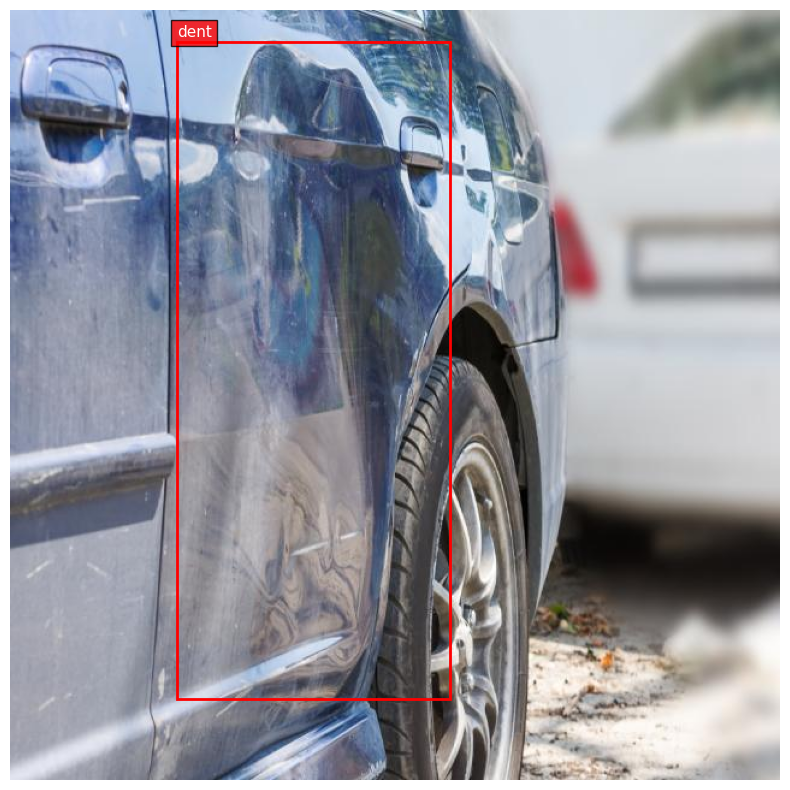

In [ ]:
img_files = os.listdir(os.path.join(base, "train", "images"))
f = random.choice(img_files)

img = Image.open(os.path.join(base, "train", "images", f))
W, H = img.size

label_file = os.path.join(base, "train", "labels", os.path.splitext(f)[0] + ".txt")
boxes = []

if os.path.exists(label_file):
    with open(label_file) as fh:
        for line in fh:
            parts = line.strip().split()
            if not parts:
                continue
            cls = int(parts[0])
            # Extract all coordinates (x, y pairs)
            coords = [float(x) for x in parts[1:]]

            if len(coords) >= 4:
                # Separate x and y coordinates
                xs = coords[0::2]
                ys = coords[1::2]

                # Convert normalized coordinates to absolute pixels
                abs_xs = [x * W for x in xs]
                abs_ys = [y * H for y in ys]

                # Determine the bounding box from polygon coordinates
                x1, x2 = min(abs_xs), max(abs_xs)
                y1, y2 = min(abs_ys), max(abs_ys)
                boxes.append((cls, x1, y1, x2, y2))
            elif len(coords) == 4:
                # If it happens to be standard bounding boxes (xc, yc, w, h)
                xc, yc, w, h = coords
                x1 = (xc - w/2) * W
                y1 = (yc - h/2) * H
                x2 = (xc + w/2) * W
                y2 = (yc + h/2) * H
                boxes.append((cls, x1, y1, x2, y2))

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)
for cls, x1, y1, x2, y2 in boxes:
    rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor="red", facecolor="none")
    ax.add_patch(rect)
    ax.text(x1, y1-4, names[cls], color="white", fontsize=11, bbox=dict(facecolor="red", alpha=0.8))
plt.axis("off")
plt.show()

In [ ]:
model = YOLO("yolov8n.pt")
model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    patience=7,
    name="carscan",
)

model.val()

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/CarDD-dataset-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=carscan-2, nbs=64, nms=None, opset=None, optimize=False

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f265aa1cde0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

In [5]:
best_model = YOLO("/content/best.pt")

metrics = best_model.val(
    data=f"{dataset.location}/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    conf=0.25,
    iou=0.45,
    plots=True,             # يحفظ confusion matrix + PR curves
    save_json=True,
    project="runs/eval",
    name="test_run",
)

print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1448.4±552.1 MB/s, size: 44.3 KB)
val: Scanning /content/CarDD-dataset-1/test/labels... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 1.3Kit/s 0.3s
val: New cache created: /content/CarDD-dataset-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 3.9it/s 6.5s
                   all        400        834      0.755      0.683      0.667      0.526
                 crack         49         81      0.497      0.333      0.305      0.167
                  dent        168        248      0.756       0.52       0.53       0.31
         glass shatter         60         60      0.968          1      0.993      0.912
           lamp broken         60         63      0.866      0.746    

In [7]:
class_names = ["crack", "dent", "glass shatter", "lamp broken", "scratch", "tire flat"]
df = pd.DataFrame({
    "class": class_names,
    "precision": metrics.box.p,
    "recall": metrics.box.r,
    "mAP50": metrics.box.ap50,
    "mAP50-95": metrics.box.maps, })

df = df.round(4)
print(df.to_string(index=False))

# تنبيه لو فيه كلاس ضعيف
weak = df[df["mAP50"] < 0.5]
if len(weak) > 0:
    print("Weak Class(mAP50 < 0.5): ")
    for _, row in weak.iterrows():
        print(f"   - {row['class']}: mAP50={row['mAP50']}, recall={row['recall']}")
else:
    print("all Classes  mAP50 >= 0.5")

        class  precision  recall  mAP50  mAP50-95
        crack     0.4972  0.3333 0.3053    0.1670
         dent     0.7559  0.5202 0.5298    0.3099
glass shatter     0.9677  1.0000 0.9934    0.9122
  lamp broken     0.8661  0.7460 0.7251    0.5788
      scratch     0.6193  0.5655 0.5006    0.2999
    tire flat     0.8245  0.9355 0.9504    0.8896
Weak Class(mAP50 < 0.5): 
   - crack: mAP50=0.3053, recall=0.3333


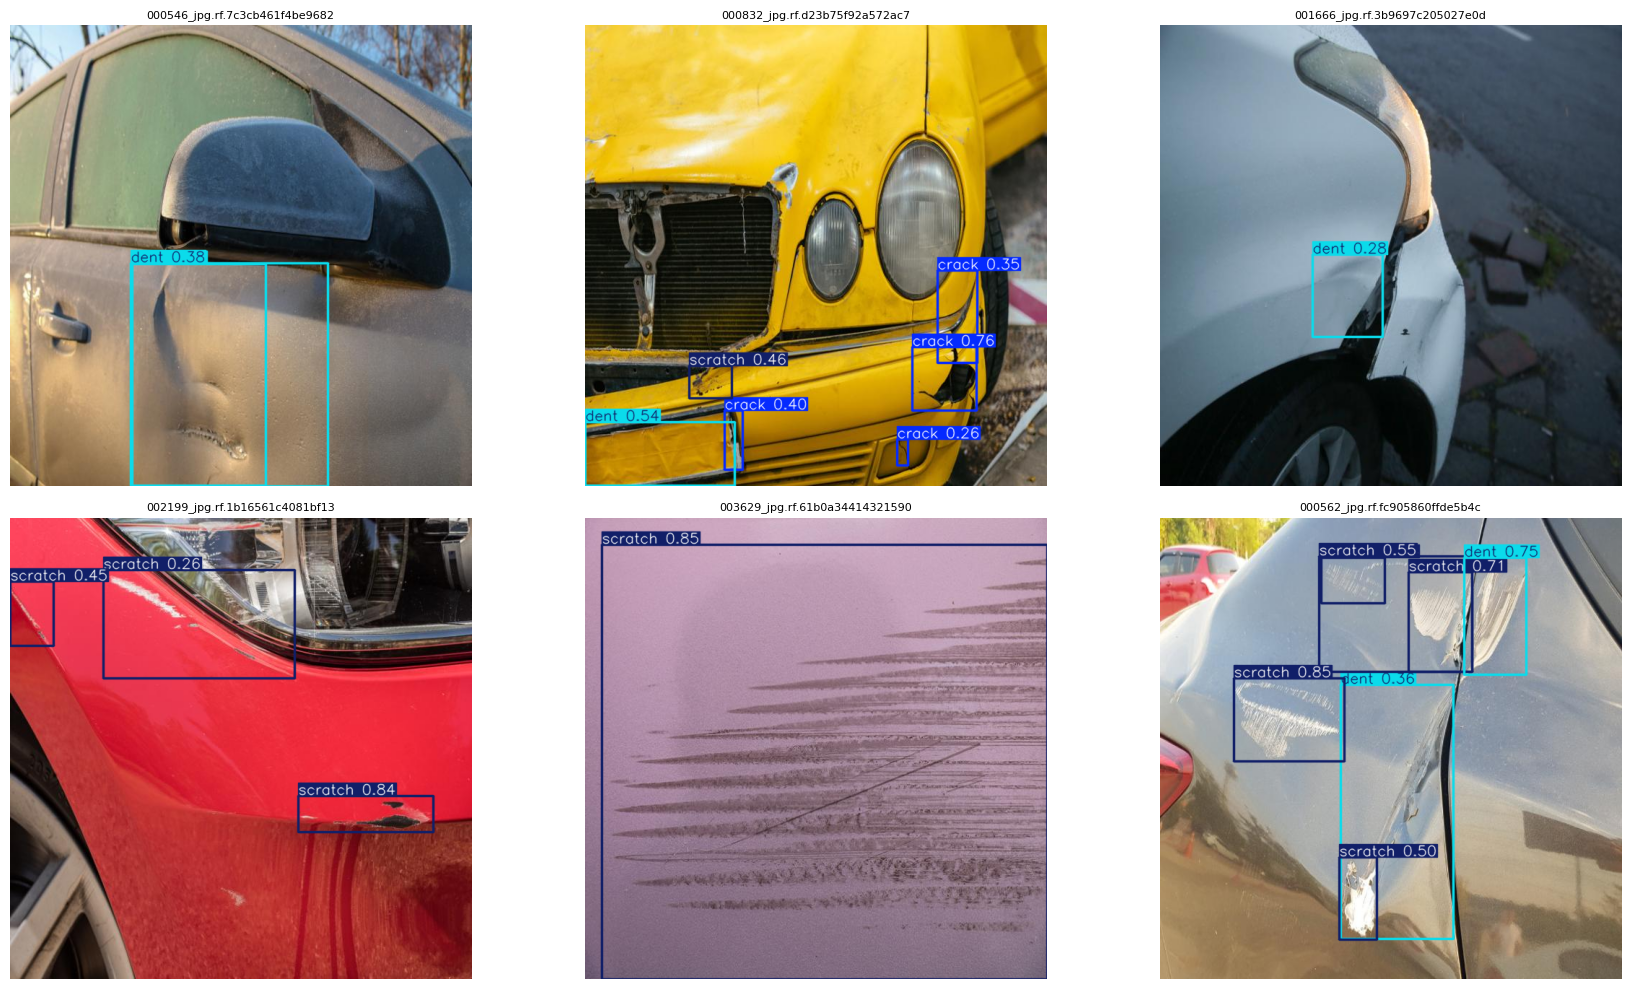

In [8]:
test_dir = os.path.join(dataset.location, "test", "images")
samples = random.sample(os.listdir(test_dir), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, fname in zip(axes.flatten(), samples):
    img_path = os.path.join(test_dir, fname)
    results = best_model.predict(img_path, conf=0.25, verbose=False)
    annotated = results[0].plot()                          #
    annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    ax.imshow(annotated)
    ax.set_title(fname[:30], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()


image 1/1 /content/OIP.jpg: 448x640 1 dent, 49.0ms
Speed: 3.1ms preprocess, 49.0ms inference, 1.9ms postprocess per image at shape (1, 3, 448, 640)


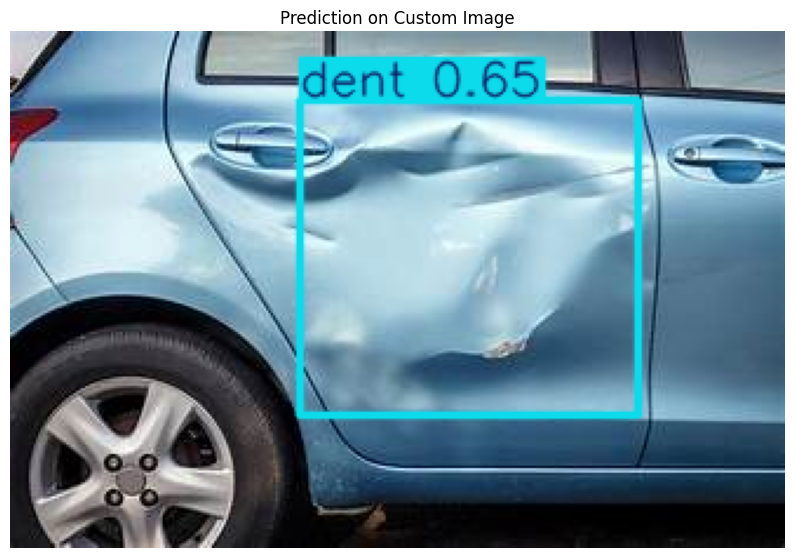

In [9]:
# Predict on the custom image
custom_image_path = "/content/OIP.jpg"

if os.path.exists(custom_image_path):
    results = best_model.predict(custom_image_path, conf=0.25, verbose=True)

    # Render results
    annotated_img = results[0].plot()
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    # Display the result
    plt.figure(figsize=(10, 10))
    plt.imshow(annotated_img)
    plt.axis("off")
    plt.title("Prediction on Custom Image")
    plt.show()
else:
    print(f"Error: The file {custom_image_path} does not exist.")